# LAB | Chaos agent: tools, lore, less questionable judgments

## Objective

Build a **strict complaint processor** for *NormalObjects* with LangGraph.
Every complaint follows a fixed path, so every answer can be **traced**.

---
## Step 1: Setup and State Definition

In [1]:
%pip install -U langgraph langchain-openai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

# Load environment variables
load_dotenv()

# Check whether the API key is available
print("OpenAI API Key loaded:", bool(os.getenv("OPENAI_API_KEY")))

# Initialize the language model
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


In [3]:
# Define the shared state for our complaint workflow

class ComplaintState(TypedDict):
    complaint: str
    category: str
    workflow_path: List[str]
    status: str

    is_valid: bool | None
    validation_reason: str

    evidence: str
    investigation: str
    resolution: str
    closure: str

# Display the state structure
print(ComplaintState.__annotations__)

{'complaint': <class 'str'>, 'category': <class 'str'>, 'workflow_path': typing.List[str], 'status': <class 'str'>, 'is_valid': bool | None, 'validation_reason': <class 'str'>, 'evidence': <class 'str'>, 'investigation': <class 'str'>, 'resolution': <class 'str'>, 'closure': <class 'str'>}


In [4]:
# Create an initial state for a sample complaint

initial_state: ComplaintState = {
    "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
    "category": "",
    "workflow_path": [],
    "status": "pending",
    "is_valid": None,
    "validation_reason": "",
    "evidence": "",
    "investigation": "",
    "resolution": "",
    "closure": ""
}

# Display the initial state
for key, value in initial_state.items():
    print(f"{key}: {value}")

complaint: The Downside Up portal opens at different times each day. How do I predict when?
category: 
workflow_path: []
status: pending
is_valid: None
validation_reason: 
evidence: 
investigation: 
resolution: 
closure: 


---
## Step 2: Define Workflow Nodes

In [5]:
# Define valid complaint categories
VALID_CATEGORIES = [
    "portal",
    "monster",
    "psychic",
    "environmental"
]

# Knowledge base: official Downside Up rules
LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",

    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",

    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",

    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

# Verify the available categories and knowledge
print("Valid categories:", VALID_CATEGORIES)
print("Knowledge base entries:", len(LORE))

Valid categories: ['portal', 'monster', 'psychic', 'environmental']
Knowledge base entries: 4


In [6]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint."""

    print("\n[INTAKE] Processing complaint...")

    # Get the complaint from the state
    complaint = state["complaint"]

    # Ask the LLM to categorize the complaint
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:

- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name
(portal, monster, psychic, environmental, or other)."""

    # Call the language model
    response = llm.invoke([
        HumanMessage(content=categorization_prompt)
    ])

    # Extract and normalize the category
    category = response.content.strip().lower()

    # Update the shared workflow state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")

    return new_state

In [7]:
# Test the intake node

intake_result = intake_node(initial_state)

print("\nUpdated category:", intake_result["category"])
print("Workflow path:", intake_result["workflow_path"])
print("Current status:", intake_result["status"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

Updated category: portal
Workflow path: ['intake']
Current status: intake


In [8]:
def validate_node(state: ComplaintState) -> ComplaintState:
    """Step 2: Validate the complaint category."""

    print("\n[VALIDATE] Checking complaint category...")

    # Get the category assigned by the intake node
    category = state["category"]

    # Check whether the category is allowed
    is_valid = category in VALID_CATEGORIES

    # Document the reason for the decision
    if is_valid:
        reason = f"Category '{category}' is allowed."
    else:
        reason = f"Category '{category}' is not allowed."

    # Update the shared workflow state
    new_state = {
        **state,
        "is_valid": is_valid,
        "validation_reason": reason,
        "workflow_path": state.get("workflow_path", []) + ["validate"],
        "status": "validate"
    }

    print(f"[VALIDATE] Valid: {is_valid}")
    print(f"[VALIDATE] Reason: {reason}")

    return new_state

In [9]:
# Test the validation node with our intake result

validation_result = validate_node(intake_result)

print("\nValidation result:", validation_result["is_valid"])
print("Validation reason:", validation_result["validation_reason"])
print("Workflow path:", validation_result["workflow_path"])
print("Current status:", validation_result["status"])


[VALIDATE] Checking complaint category...
[VALIDATE] Valid: True
[VALIDATE] Reason: Category 'portal' is allowed.

Validation result: True
Validation reason: Category 'portal' is allowed.
Workflow path: ['intake', 'validate']
Current status: validate


In [10]:
def investigate_node(state: ComplaintState) -> ComplaintState:
    """Step 3: Investigate complaint using official LORE."""

    print("\n[INVESTIGATE] Investigating complaint...")

    # Get complaint and category from state
    complaint = state["complaint"]
    category = state["category"]

    # Ensure the complaint is valid
    if state["is_valid"] is not True or category not in LORE:
        raise ValueError("Cannot investigate an invalid complaint.")

    # Retrieve the relevant source information
    lore_evidence = LORE[category]

    # Create a strictly grounded investigation prompt
    investigation_prompt = f"""You are investigating a complaint
about the fictional Downside Up world.

Complaint:
{complaint}

Official LORE:
{lore_evidence}

Instructions:
- Answer using ONLY the official LORE provided above.
- Do not invent additional facts or explanations.
- If the LORE does not fully answer the question,
  clearly state what cannot be determined.
- Keep the investigation short and clear.

Investigation:"""

    # Generate the investigation using the LLM
    response = llm.invoke([
        HumanMessage(content=investigation_prompt)
    ])

    investigation = response.content.strip()

    # Update the workflow state
    new_state = {
        **state,
        "evidence": lore_evidence,
        "investigation": investigation,
        "workflow_path": state.get("workflow_path", []) + ["investigate"],
        "status": "investigate"
    }

    print(f"[INVESTIGATE] Evidence: {lore_evidence}")
    print(f"[INVESTIGATE] Result: {investigation}")

    return new_state

In [11]:
# Test the investigation node

investigation_result = investigate_node(validation_result)

print("\n--- Investigation Summary ---")
print("Category:", investigation_result["category"])
print("Evidence:", investigation_result["evidence"])
print("Investigation:", investigation_result["investigation"])
print("Workflow path:", investigation_result["workflow_path"])
print("Current status:", investigation_result["status"])


[INVESTIGATE] Investigating complaint...
[INVESTIGATE] Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] Result: The timing of the Downside Up portal openings follows electrical activity rather than a set clock schedule. Therefore, it cannot be determined exactly when the portals will open each day, as this depends on the fluctuations in electrical activity.

--- Investigation Summary ---
Category: portal
Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
Investigation: The timing of the Downside Up portal openings follows electrical activity rather than a set clock schedule. Therefore, it cannot be determined exactly when the portals will open each day, as this depends on the fluctuations in electrical activity.
Workflow path: ['intake', 'validate', 'investigate']
Current status: investigate


In [12]:
def resolve_node(state: ComplaintState) -> ComplaintState:
    """Step 4: Generate a resolution based on the investigation."""

    print("\n[RESOLVE] Generating resolution...")

    # Get the complaint and investigation from state
    complaint = state["complaint"]
    investigation = state["investigation"]

    # Ensure an investigation exists
    if state["is_valid"] is not True or not investigation.strip():
        raise ValueError("Cannot resolve without a valid investigation.")

    # Create a grounded resolution prompt
    resolution_prompt = f"""You are resolving a complaint
about the fictional Downside Up world.

Original complaint:
{complaint}

Investigation findings:
{investigation}

Instructions:
- Provide a short, helpful resolution.
- Base your answer ONLY on the investigation findings.
- Do not invent facts, solutions, or predictions.
- If no exact solution is supported, explain the limitation.
- Keep your response to 1-3 sentences.

Resolution:"""

    # Generate resolution using the LLM
    response = llm.invoke([
        HumanMessage(content=resolution_prompt)
    ])

    resolution = response.content.strip()

    if not resolution:
        raise ValueError("The LLM returned an empty resolution.")

    # Update the workflow state
    new_state = {
        **state,
        "resolution": resolution,
        "workflow_path": state.get("workflow_path", []) + ["resolve"],
        "status": "resolve"
    }

    print(f"[RESOLVE] Resolution: {resolution}")

    return new_state

In [13]:
# Test the resolution node

resolution_result = resolve_node(investigation_result)

print("\n--- Resolution Summary ---")
print("Complaint:", resolution_result["complaint"])
print("Evidence:", resolution_result["evidence"])
print("Resolution:", resolution_result["resolution"])
print("Workflow path:", resolution_result["workflow_path"])
print("Current status:", resolution_result["status"])


[RESOLVE] Generating resolution...
[RESOLVE] Resolution: The timing of the Downside Up portal openings is influenced by fluctuations in electrical activity rather than a fixed schedule, making it impossible to predict exact opening times each day. Unfortunately, this means there is no reliable method to determine when the portals will open.

--- Resolution Summary ---
Complaint: The Downside Up portal opens at different times each day. How do I predict when?
Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
Resolution: The timing of the Downside Up portal openings is influenced by fluctuations in electrical activity rather than a fixed schedule, making it impossible to predict exact opening times each day. Unfortunately, this means there is no reliable method to determine when the portals will open.
Workflow path: ['intake', 'validate', 'investigate', 'resolve']
Current status: resolve


In [14]:
def close_node(state: ComplaintState) -> ComplaintState:
    """Step 5: Close a successfully processed complaint."""

    print("\n[CLOSE] Closing complaint...")

    # Check whether a valid resolution and evidence exist
    if (
        state["is_valid"] is not True
        or not state["resolution"].strip()
        or not state["evidence"].strip()
    ):
        raise ValueError(
            "Cannot close a complaint without validation, evidence, and resolution."
        )

    # Create a final closing message
    closure_message = (
        "Your complaint has been processed.\n"
        f"Resolution: {state['resolution']}\n"
        "Status: Closed"
    )

    # Update the workflow state
    new_state = {
        **state,
        "closure": closure_message,
        "workflow_path": state.get("workflow_path", []) + ["close"],
        "status": "closed"
    }

    print("[CLOSE] Complaint closed successfully.")
    print(f"[CLOSE] Message:\n{closure_message}")

    return new_state

In [15]:
# Test the closure node

closure_result = close_node(resolution_result)

print("\n--- Closure Summary ---")
print("Final status:", closure_result["status"])
print("Closure message:", closure_result["closure"])
print("Workflow path:", closure_result["workflow_path"])


[CLOSE] Closing complaint...
[CLOSE] Complaint closed successfully.
[CLOSE] Message:
Your complaint has been processed.
Resolution: The timing of the Downside Up portal openings is influenced by fluctuations in electrical activity rather than a fixed schedule, making it impossible to predict exact opening times each day. Unfortunately, this means there is no reliable method to determine when the portals will open.
Status: Closed

--- Closure Summary ---
Final status: closed
Closure message: Your complaint has been processed.
Resolution: The timing of the Downside Up portal openings is influenced by fluctuations in electrical activity rather than a fixed schedule, making it impossible to predict exact opening times each day. Unfortunately, this means there is no reliable method to determine when the portals will open.
Status: Closed
Workflow path: ['intake', 'validate', 'investigate', 'resolve', 'close']


In [16]:
def reject_node(state: ComplaintState) -> ComplaintState:
    """Reject complaints that fail validation."""

    print("\n[REJECT] Rejecting complaint...")

    # Ensure the complaint failed validation
    if state["is_valid"] is not False:
        raise ValueError(
            "Only invalid complaints can be rejected."
        )

    # Get the reason from the validation node
    reason = state["validation_reason"]

    # Create a rejection message
    rejection_message = (
        "Your complaint cannot be processed.\n"
        f"Reason: {reason}\n"
        "Status: Rejected"
    )

    # Update the workflow state
    new_state = {
        **state,
        "closure": rejection_message,
        "workflow_path": state.get("workflow_path", []) + ["reject"],
        "status": "rejected"
    }

    print(f"[REJECT] Message:\n{rejection_message}")

    return new_state

In [17]:
# Create a sample invalid complaint
invalid_state = {
    **initial_state,
    "complaint": "My pizza delivery arrived cold.",
    "category": "other",
    "workflow_path": ["intake"],
    "status": "intake"
}

# Validate the complaint
invalid_validation_result = validate_node(invalid_state)

# Reject the complaint
rejection_result = reject_node(invalid_validation_result)

# Display the results
print("\n--- Rejection Summary ---")
print("Complaint:", rejection_result["complaint"])
print("Category:", rejection_result["category"])
print("Valid:", rejection_result["is_valid"])
print("Rejection message:", rejection_result["closure"])
print("Workflow path:", rejection_result["workflow_path"])
print("Final status:", rejection_result["status"])


[VALIDATE] Checking complaint category...
[VALIDATE] Valid: False
[VALIDATE] Reason: Category 'other' is not allowed.

[REJECT] Rejecting complaint...
[REJECT] Message:
Your complaint cannot be processed.
Reason: Category 'other' is not allowed.
Status: Rejected

--- Rejection Summary ---
Complaint: My pizza delivery arrived cold.
Category: other
Valid: False
Rejection message: Your complaint cannot be processed.
Reason: Category 'other' is not allowed.
Status: Rejected
Workflow path: ['intake', 'validate', 'reject']
Final status: rejected


---
## Step 3: Build the Graph

In [18]:
def route_after_validation(
    state: ComplaintState
) -> Literal["investigate", "reject"]:
    """Choose the next node based on validation."""

    if state["is_valid"] is True:
        return "investigate"

    elif state["is_valid"] is False:
        return "reject"

    else:
        raise ValueError(
            "Complaint must be validated before routing."
        )

In [19]:
# Test routing for a valid complaint
valid_route = route_after_validation(validation_result)

# Test routing for an invalid complaint
invalid_route = route_after_validation(invalid_validation_result)

print("Valid complaint routes to:", valid_route)
print("Invalid complaint routes to:", invalid_route)

Valid complaint routes to: investigate
Invalid complaint routes to: reject


In [20]:
# Create the LangGraph workflow
workflow = StateGraph(ComplaintState)

# Register all workflow nodes
workflow.add_node("intake", intake_node)
workflow.add_node("validate", validate_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)
workflow.add_node("reject", reject_node)

# Display registered nodes
print("Registered nodes:", list(workflow.nodes.keys()))

Registered nodes: ['intake', 'validate', 'investigate', 'resolve', 'close', 'reject']


In [21]:
# Connect START to the intake node
workflow.add_edge(START, "intake")

# Intake always leads to validation
workflow.add_edge("intake", "validate")

# Inspect the registered edges
print("Configured edges:", workflow.edges)

Configured edges: {('__start__', 'intake'), ('intake', 'validate')}


In [22]:
# Add conditional routing after validation

workflow.add_conditional_edges(
    "validate",
    route_after_validation,
    {
        "investigate": "investigate",
        "reject": "reject"
    }
)

print("Conditional routing successfully added.")

Conditional routing successfully added.


In [23]:
# Complete the valid complaint workflow
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")
workflow.add_edge("close", END)

# Complete the rejected complaint workflow
workflow.add_edge("reject", END)

# Display all configured regular edges
print("Workflow edges:")
for edge in sorted(workflow.edges):
    print(f"{edge[0]} -> {edge[1]}")

print("\nAll workflow connections added successfully.")

Workflow edges:
__start__ -> intake
close -> __end__
intake -> validate
investigate -> resolve
reject -> __end__
resolve -> close

All workflow connections added successfully.


In [24]:
# Compile the LangGraph workflow
app = workflow.compile()

# Confirm successful compilation
print("Graph compiled successfully!")
print("Graph type:", type(app).__name__)

# Display all nodes in the compiled graph
print("\nCompiled graph nodes:")
for node in app.get_graph().nodes:
    print(f"- {node}")

Graph compiled successfully!
Graph type: CompiledStateGraph

Compiled graph nodes:
- __start__
- intake
- validate
- investigate
- resolve
- close
- reject
- __end__


---
## Step 4: Test the Workflow

In [25]:
# Test 1: Run a valid complaint through the complete graph

print("=== TEST 1: VALID COMPLAINT ===")

# Create a fresh state for the workflow
test_state = {
    **initial_state,
    "workflow_path": []
}

# Execute the complete LangGraph workflow
result = app.invoke(test_state)

# Display the final results
print("\n=== FINAL WORKFLOW RESULT ===")
print("Complaint:", result["complaint"])
print("Category:", result["category"])
print("Valid:", result["is_valid"])
print("Evidence:", result["evidence"])
print("Investigation:", result["investigation"])
print("Resolution:", result["resolution"])
print("Workflow path:", result["workflow_path"])
print("Final status:", result["status"])

=== TEST 1: VALID COMPLAINT ===

[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking complaint category...
[VALIDATE] Valid: True
[VALIDATE] Reason: Category 'portal' is allowed.

[INVESTIGATE] Investigating complaint...
[INVESTIGATE] Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] Result: The timing of the Downside Up portal opening is determined by electrical activity, not by the clock. Therefore, it cannot be predicted based on a specific schedule or time of day. The exact relationship between electrical activity and portal openings is not detailed in the official LORE, so the specific times cannot be determined.

[RESOLVE] Generating resolution...
[RESOLVE] Resolution: The timing of the Downside Up portal opening is influenced by electrical activity rather than a fixed schedule, making it unpredictable. Unfortunately, the specific relationship between this activi

In [26]:
# Test 2: Run an invalid complaint through the complete graph

print("=== TEST 2: INVALID COMPLAINT ===")

# Create a fresh state with an unrelated complaint
invalid_test_state = {
    **initial_state,
    "complaint": "My pizza delivery arrived cold.",
    "workflow_path": []
}

# Execute the complete workflow
invalid_result = app.invoke(invalid_test_state)

# Display the final results
print("\n=== FINAL REJECTION RESULT ===")
print("Complaint:", invalid_result["complaint"])
print("Category:", invalid_result["category"])
print("Valid:", invalid_result["is_valid"])
print("Validation reason:", invalid_result["validation_reason"])
print("Closure:", invalid_result["closure"])
print("Workflow path:", invalid_result["workflow_path"])
print("Final status:", invalid_result["status"])

# Verify that the investigation was skipped
print("\n=== GUARDRAIL CHECK ===")
print("Investigation skipped:", "investigate" not in invalid_result["workflow_path"])
print("Resolution skipped:", "resolve" not in invalid_result["workflow_path"])

=== TEST 2: INVALID COMPLAINT ===

[INTAKE] Processing complaint...
[INTAKE] Categorized as: other

[VALIDATE] Checking complaint category...
[VALIDATE] Valid: False
[VALIDATE] Reason: Category 'other' is not allowed.

[REJECT] Rejecting complaint...
[REJECT] Message:
Your complaint cannot be processed.
Reason: Category 'other' is not allowed.
Status: Rejected

=== FINAL REJECTION RESULT ===
Complaint: My pizza delivery arrived cold.
Category: other
Valid: False
Validation reason: Category 'other' is not allowed.
Closure: Your complaint cannot be processed.
Reason: Category 'other' is not allowed.
Status: Rejected
Workflow path: ['intake', 'validate', 'reject']
Final status: rejected

=== GUARDRAIL CHECK ===
Investigation skipped: True
Resolution skipped: True


In [27]:
# Step 4c: Test all five sample complaints

test_cases = [
    (
        "The Downside Up portal opens at different times each day. How do I predict when?",
        "portal"
    ),
    (
        "Demogorgons sometimes work together and sometimes fight. What's their deal?",
        "monster"
    ),
    (
        "El can move things with her mind but can't lift heavy rocks. Why?",
        "psychic"
    ),
    (
        "Why do creatures and power lines react so strangely together?",
        "environmental"
    ),
    (
        "This is not a valid complaint about something random",
        "other"
    )
]

# Store results for later evaluation
test_results = []

for number, (complaint, expected_category) in enumerate(test_cases, start=1):

    print(f"\n{'=' * 50}")
    print(f"TEST CASE {number}")
    print(f"{'=' * 50}")

    # Create a fresh state
    current_state = {
        **initial_state,
        "complaint": complaint,
        "workflow_path": []
    }

    # Run the complete LangGraph workflow
    current_result = app.invoke(current_state)

    # Save the result
    test_results.append(current_result)

    # Compare predicted and expected categories
    category_correct = (
        current_result["category"] == expected_category
    )

    print("\n--- TEST SUMMARY ---")
    print("Expected category:", expected_category)
    print("Actual category:", current_result["category"])
    print("Category correct:", category_correct)
    print("Final status:", current_result["status"])
    print("Workflow path:", current_result["workflow_path"])

print("\nAll test cases completed.")


TEST CASE 1

[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking complaint category...
[VALIDATE] Valid: True
[VALIDATE] Reason: Category 'portal' is allowed.

[INVESTIGATE] Investigating complaint...
[INVESTIGATE] Evidence: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] Result: The timing of the Downside Up portal openings follows electrical activity rather than a set clock schedule. Therefore, it cannot be determined exactly when the portals will open each day, as this depends on the fluctuations in electrical activity.

[RESOLVE] Generating resolution...
[RESOLVE] Resolution: The timing of the Downside Up portal openings is influenced by fluctuations in electrical activity, making it impossible to predict exact opening times each day. Unfortunately, without a consistent schedule, you will need to remain attentive to changes in electrical activity to anticipate when the po

In [28]:
# Step 4d: Evaluate all test results

total_tests = len(test_results)

# Count correct categories
correct_categories = sum(
    result["category"] == expected
    for result, (_, expected) in zip(test_results, test_cases)
)

# Count completed and rejected complaints
closed_count = sum(
    result["status"] == "closed"
    for result in test_results
)

rejected_count = sum(
    result["status"] == "rejected"
    for result in test_results
)

# Verify the expected execution paths
valid_path = [
    "intake", "validate", "investigate", "resolve", "close"
]

rejected_path = [
    "intake", "validate", "reject"
]

correct_paths = sum(
    result["workflow_path"] == (
        valid_path if expected in VALID_CATEGORIES else rejected_path
    )
    for result, (_, expected) in zip(test_results, test_cases)
)

# Verify that the original LORE evidence was preserved
evidence_matches = sum(
    result["evidence"] == LORE.get(result["category"])
    for result in test_results
    if result["status"] == "closed"
)

print("=== WORKFLOW EVALUATION ===")
print(f"Total tests: {total_tests}")
print(f"Correct categories: {correct_categories}/{total_tests}")
print(f"Category accuracy: {correct_categories / total_tests:.0%}")
print(f"Correct workflow paths: {correct_paths}/{total_tests}")
print(f"Closed complaints: {closed_count}")
print(f"Rejected complaints: {rejected_count}")
print(f"Evidence matches LORE: {evidence_matches}/{closed_count}")

=== WORKFLOW EVALUATION ===
Total tests: 5
Correct categories: 5/5
Category accuracy: 100%
Correct workflow paths: 5/5
Closed complaints: 4
Rejected complaints: 1
Evidence matches LORE: 4/4


---
## Step 5: Visualize the Workflow Path

In [29]:
def visualize_workflow_path(state: ComplaintState) -> None:
    """Display the execution path of a processed complaint."""

    # Extract information from the state
    complaint = state["complaint"]
    category = state["category"]
    path = state["workflow_path"]
    status = state["status"]

    print("\n" + "=" * 60)
    print("COMPLAINT WORKFLOW EXECUTION")
    print("=" * 60)

    print(f"Complaint: {complaint}")
    print(f"Category: {category}")
    print(f"Valid: {state['is_valid']}")

    # Format the execution path
    print("\nExecution Path:")

    if path:
        formatted_path = (
            "START -> "
            + " -> ".join(node.upper() for node in path)
            + " -> END"
        )
        print(formatted_path)
    else:
        print("No workflow steps executed.")

    print(f"\nTotal nodes executed: {len(path)}")
    print(f"Final status: {status}")
    print("=" * 60)


# Visualize the valid and rejected paths from Step 4c
visualize_workflow_path(test_results[0])
visualize_workflow_path(test_results[4])


COMPLAINT WORKFLOW EXECUTION
Complaint: The Downside Up portal opens at different times each day. How do I predict when?
Category: portal
Valid: True

Execution Path:
START -> INTAKE -> VALIDATE -> INVESTIGATE -> RESOLVE -> CLOSE -> END

Total nodes executed: 5
Final status: closed

COMPLAINT WORKFLOW EXECUTION
Complaint: This is not a valid complaint about something random
Category: other
Valid: False

Execution Path:
START -> INTAKE -> VALIDATE -> REJECT -> END

Total nodes executed: 3
Final status: rejected


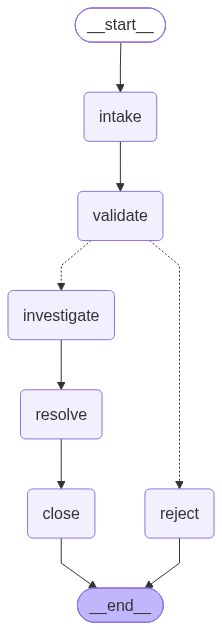

In [30]:
# Step 5b: Visualize the complete LangGraph

# Get the compiled graph structure
graph_structure = app.get_graph()

try:
    # Render the graph as a PNG image
    display(Image(graph_structure.draw_mermaid_png()))

except Exception as error:
    print("PNG visualization failed:", error)

    # Fallback: display the Mermaid diagram source
    print("\nMermaid graph definition:")
    print(graph_structure.draw_mermaid())

---
## Step 6: Compare with LangChain

### LangGraph vs. LangChain Agent Approach

**LangGraph – Structured Approach**

Our Strict Complaint Processor uses a predefined workflow with six nodes:

Intake → Validate → Investigate → Resolve → Close

Invalid complaints follow a separate rejection path.

Key advantages:
- Explicit control over workflow execution
- Deterministic validation and routing rules
- Shared state between processing steps
- Traceable execution paths
- Direct access to predefined LORE evidence

**LangChain – More Flexible Agent Approach**

A tool-calling LangChain agent could decide dynamically when to retrieve information, which tools to use, and whether further investigation is needed.

Key advantages:
- Flexible tool selection
- Adaptable to unexpected user requests
- Suitable for open-ended tasks
- Less custom orchestration code for simple agents

**Why LangGraph for This Lab?**

LangGraph is a suitable choice because complaint processing follows a clearly defined sequence.

The LLM categorizes complaints and generates explanations, while Python rules control validation and routing.

This combination provides flexibility where interpretation is needed and predictable behavior where strict rules apply.

**Limitations**

The workflow is not completely deterministic because LLM-generated content can vary.

Our evaluation achieved:
- Category accuracy: 5/5
- Correct workflow paths: 5/5
- Exact LORE evidence matches: 4/4

However, correct evidence retrieval does not guarantee that every statement in the final resolution is grounded.

For example, the portal resolution recommended monitoring electrical activity, although the official LORE does not explicitly provide this as a prediction method.

A production system would benefit from additional grounding validation before closing complaints.

**Conclusion**

LangGraph gives us explicit control over the complaint-processing workflow while still allowing LLM-based interpretation.

For this structured use case, that balance is preferable to letting an agent independently determine the entire sequence of actions.